# SYNCEDSTRUCTURE
### **A Class to handle, crossreference and annotate Structural Proteomics Data**

Credits:
LICENCES:

In [1]:
### <DEPENDENCIES and SyncedStructure Methods display> 
import re, urllib.request, requests, io, copy, os, pickle
import math, string
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch, Rectangle
import pandas as pd
import seaborn as sns
from synced_structure import SyncedStructure
from viz3d import side_by_side

def get_uniprot(uid):
    u = str(uid).strip().upper()
    if not re.match(r"^([OPQ][0-9][A-Z0-9]{3}[0-9]|[A-NR-Z][0-9]([A-Z][A-Z0-9]{2}[0-9]){1,2})(-\d+)?$", u):
        raise ValueError()
    buf = io.StringIO(urllib.request.urlopen(f"https://rest.uniprot.org/uniprotkb/{u}.fasta").read().decode())
    return u, "".join(buf.read().splitlines()[1:])


pd.set_option("display.width", 1000)
pd.set_option("display.max_columns", None)
pd.set_option('display.max_colwidth', 20)
pd.set_option("display.max_rows", 100)

synced_structure_options = dir(SyncedStructure)
d = [x for x in synced_structure_options if x.startswith("__")]
h = [x for x in synced_structure_options
    if x.startswith("_") and not x.startswith("__")]
e = [x for x in synced_structure_options if not x.startswith("_")]
for g in (d, h, e):
  if g:
    [print(g[i : i + 4]) for i in range(0, len(g), 4)]
    print()
### <\DEPENDENCIES and SyncedStructure Methods display>

### <HELPERS_VIZ>
set1_palette = [
    "#e41a1c",
    "#377eb8",
    "#4daf4a",
    "#984ea3",
]

def plot_grid_with_letters(plot_funcs, sizes, ncols=2, panel_labels=True, main_title=None, wspace=0.2, hspace=0.2):
    n = len(plot_funcs)
    nrows = math.ceil(n / ncols)
    full_sizes = sizes + [sizes[-1]] * (nrows * ncols - n)
    size_grid = [full_sizes[i*ncols:(i+1)*ncols] for i in range(nrows)]
    row_heights = [max(row) for row in size_grid]
    col_widths = [max(size_grid[r][c] for r in range(nrows)) for c in range(ncols)]
    fig = plt.figure(figsize=(sum(col_widths), sum(row_heights)))
    gs = fig.add_gridspec(nrows, ncols, width_ratios=col_widths, height_ratios=row_heights, wspace=wspace, hspace=hspace)
    if main_title:
        fig.suptitle(main_title, fontsize=16, fontweight='bold', y=0.95)
    axes = []
    for i, f in enumerate(plot_funcs):
        r, c = divmod(i, ncols)
        ax = fig.add_subplot(gs[r, c])
        f(ax=ax)
        if panel_labels and i < len(string.ascii_uppercase):
            ax.text(-0.12, 1.05, string.ascii_uppercase[i], transform=ax.transAxes, fontsize=14, fontweight='bold', va='bottom', ha='right')
        axes.append(ax)
    plt.show()
    return fig, axes

### <\HELPERS-VIZ>

['__class__', '__contains__', '__delattr__', '__dict__']
['__dir__', '__doc__', '__eq__', '__firstlineno__']
['__format__', '__ge__', '__getattribute__', '__getitem__']
['__getstate__', '__gt__', '__hash__', '__init__']
['__init_subclass__', '__iter__', '__le__', '__len__']
['__lt__', '__module__', '__ne__', '__new__']
['__reduce__', '__reduce_ex__', '__repr__', '__setattr__']
['__sizeof__', '__static_attributes__', '__str__', '__subclasshook__']
['__weakref__']

['_angles_overlay', '_apply_chain_options', '_atom_contacts', '_atom_pair_maps']
['_auth_of', '_block_entries', '_build_chains', '_ca_records']
['_chain_colors', '_chain_contact_partners', '_chain_description_map', '_chain_entity_map']
['_chain_geometry', '_chain_name', '_checked_matrix', '_clean_val']
['_compute_interface', '_compute_local_alignment', '_coords_touch', '_draw_pair']
['_entity_sequences', '_external_refs_for_entity', '_gray_matrix', '_heavy_atoms']
['_hydrophobicity', '_keep_mapped', '_label_of', '_local_alignm

### ZIKV Monoclonal Antibodies

We use `A0A142I5B9` from UniProtKB as reference sequence to synchronize atomic coordinates

| Monoclonal Antibody | PDB ID | Reference & Description                                                                                                                                                                                                                                                 |
| ------------------- | ------ | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **ZIKV-195**        | `6MID` | Cryo-EM structure of the ZIKV virion complexed with ZIKV-195 Fab fragments. Long et al. (2019), *PNAS*. [DOI](https://doi.org/10.1073/pnas.1815432116).                                                                                                                 |
| **EDE2 A11**        | `5LCV` | Crystal structure of the Zika virus envelope protein in complex with the broadly neutralizing antibody EDE2 A11. Barba-Spaeth et al. (2016), *Nature*. [DOI](https://doi.org/10.1038/nature18938).                                                                      |
| **EDE1 C8**         | `5LBS` | Crystal structure of the Zika virus envelope protein in complex with EDE1 C8, a broadly neutralizing antibody recognizing a conserved epitope shared between Zika and dengue viruses. Barba-Spaeth et al. (2016), *Nature*. [DOI](https://doi.org/10.1038/nature18938). |
| **ZIKV-117**        | `5KVE` | Structure of the Zika virus envelope protein in complex with ZIKV-117, a potent human monoclonal antibody targeting a quaternary epitope on the viral surface. [RCSB PDB](https://www.rcsb.org/structure/5KVE).                                                         |
| **ZKA190**          | `5Y0A` | Cryo-EM structure of Zika virus complexed with Fab of the potent human monoclonal antibody ZKA190 targeting an exposed epitope on DIII of the E protein. Wang et al. (2017), *Cell*. [DOI](https://doi.org/10.1016/j.cell.2017.09.002).                                |
| **ZV-67**           | `5KVG` | Crystal structure of the Zika-specific mouse monoclonal antibody ZV-67 bound to ZIKV envelope domain III (lateral ridge epitope). Zhao et al. (2016), *Cell*. [DOI](https://doi.org/10.1016/j.cell.2016.07.020).                                                       |

In [12]:
### <RETRIEVAL, MAPPING and VISUALIZATION>
NICKNAME = "zikv"
PDB_IDS = ["6MID", "5LCV", "5LBS", "5KVE", "5Y0A", "5KVG"]
pdb_angles = [(-17, 60, -140), (-21, -6, 86), (101, -48, -104), (-81, -13, -70), (150, -30, -37), (-50, -30, -70)]
to_remove = {
    "6MID": ["A", "B", "G"],
    "5LBS": ["B", "M", "I"]
}
upid_list = ["A0A142I5B9"]
PDBS_THERE = {
    "query": {
        "type": "terminal",
        "service": "text",
        "parameters": {
            "attribute": "rcsb_polymer_entity_container_identifiers.reference_sequence_identifiers.database_accession",
            "operator": "in",
            "value": upid_list
        }
    },
    "return_type": "entry",
    "request_options": {"paginate": {"start": 0, "rows": 250}}
}

upseq = get_uniprot(upid_list[0])
print(f"{upseq[0]}: {upseq[1][:50]}...")
synced_list = [SyncedStructure.from_rcsb_id(pid) for pid in PDB_IDS]
for pdb_id, sync in zip(PDB_IDS, synced_list):
    for c in to_remove.get(pdb_id, []):
        if c in sync.chain_ids:
            sync.remove_chain(c)
sync_summaries = []
for pdb_id, sync in zip(PDB_IDS, synced_list):
    summary = sync.summary()
    if isinstance(summary, dict):
        summary['pdb_id'] = pdb_id
        sync_summaries.append(summary)
    elif isinstance(summary, pd.DataFrame):
        summary = summary.copy()
        summary['pdb_id'] = pdb_id
        sync_summaries.append(summary)
sync_df = pd.concat(sync_summaries, ignore_index=True) if sync_summaries and isinstance(sync_summaries[0], pd.DataFrame) else pd.DataFrame(sync_summaries)
structure_neighbours = {}
matched_by_pdb = {}
for pdb_id, sync in zip(PDB_IDS, synced_list):
    try:
        mc = sync.match_chains(upseq[1])
        mc = mc[mc['query_coverage_percent'] > 1]
        matched_ids = mc['auth_chain_id'].tolist()
        partners_dict = sync._chain_contact_partners(cutoff=0.8)
        neighbour_set = set()
        for mid in matched_ids:
            neighbour_set.update(partners_dict.get(mid, []))
        neighbour_set -= set(matched_ids)
        structure_neighbours[pdb_id] = list(neighbour_set)
        matched_by_pdb[pdb_id] = matched_ids
    except Exception:
        matched_by_pdb[pdb_id] = []
        structure_neighbours[pdb_id] = []
viz_list = []
crimson = "#b8483b"
pea = "#acdf74"
base = "#c7d0be"
for pdb_id, sync, angles in zip(PDB_IDS, synced_list, pdb_angles):
    if pdb_id not in matched_by_pdb:
        continue
    matched_ids = matched_by_pdb[pdb_id]
    partners = structure_neighbours.get(pdb_id, [])
    for focus in matched_ids:
        sync.set_reference_sequence(chain_id=focus, sequence=upseq[1], remap=True)
        sync.set_external_ref(chain_id=focus, external_ref=upseq[0])
        sync.remap_chain(focus)
    title = f"Envelope ({pdb_id})"
    all_chains = sync.chain_ids
    palette = {c: base for c in all_chains}
    for c in partners:
        palette[c] = pea
    for c in matched_ids:
        palette[c] = crimson
    plot = sync.jupy_viz(title=title, colors=palette, size=200, style='sphere', angles=angles)
    viz_list.append(plot)
side_by_side(*viz_list)
### <\NAMING STRUCTURES OF INTEREST>

A0A142I5B9: MKNPKKKSGGFRIVNMLKRGVARVSPFGGLKRLPAGLLLGHGPIRMVLAI...
[PYTHON-INFO] 2026-10-17 20:23:47 | Loaded RCSB structure 6MID | execution time: 1.46s | max memory: 647.5 MB
[PYTHON-INFO] 2026-10-17 20:23:48 | Loaded RCSB structure 5LCV | execution time: 1.14s | max memory: 647.5 MB
[PYTHON-INFO] 2026-10-17 20:23:49 | Loaded RCSB structure 5LBS | execution time: 1.19s | max memory: 647.5 MB
[PYTHON-INFO] 2026-10-17 20:23:50 | Loaded RCSB structure 5KVE | execution time: 0.47s | max memory: 647.5 MB
[PYTHON-INFO] 2026-10-17 20:23:50 | Loaded RCSB structure 5Y0A | execution time: 0.27s | max memory: 647.5 MB
[PYTHON-INFO] 2026-10-17 20:23:51 | Loaded RCSB structure 5KVG | execution time: 0.65s | max memory: 647.5 MB
remapped D
remapped F
remapped C
remapped E
[PYTHON-INFO] 2026-10-17 20:23:52 | Rendered view of 6MID at angles (-17, 60, -140) | execution time: 0.72s | max memory: 647.5 MB
remapped A
remapped B
[PYTHON-INFO] 2026-10-17 20:23:53 | Rendered view of 5LCV at angles (-21, -6,

In [14]:
### <NAMING STRUCTURES OF INTEREST>
pdb_6mid = synced_list[0]
pdb_5lcv = synced_list[1]
pdb_5lbs = synced_list[2]
pdb_5kve = synced_list[3]
pdb_5y0a = synced_list[4]
pdb_5kvg = synced_list[5]

for pdb_id, sync in zip(PDB_IDS, synced_list):
    print(f"{"*"*40}")
    print(pdb_id)
    print(set(sync.summary()['description']))

### <\NAMING STRUCTURES OF INTEREST>

****************************************
6MID
{'monoclonal antibody ZIKV-195 heavy chain', 'monoclonal antibody ZIKV-195 light chain', '2-acetamido-2-deoxy-beta-D-glucopyranose-(1-4)-2-acetamido-2-deoxy-beta-D-glucopyranose', 'M protein', 'E protein'}
****************************************
5LCV
{'BROADLY NEUTRALIZING HUMAN ANTIBODY EDE2 A11', 'beta-D-mannopyranose-(1-4)-2-acetamido-2-deoxy-beta-D-glucopyranose-(1-4)-[alpha-L-fucopyranose-(1-6)]2-acetamido-2-deoxy-beta-D-glucopyranose', 'Polyprotein'}
****************************************
5LBS
{'envelope protein E', 'BROADLY NEUTRALIZING HUMAN ANTIBODY EDE1 C8'}
****************************************
5KVE
{'Genome polyprotein', 'ZV-48 Antibody scFv'}
****************************************
5Y0A
{'variable region of Fab ZKA190 heavy chain', 'variable region of Fab ZKA190 light chain', 'protein E'}
****************************************
5KVG
{'ZV-67 Antibody Fab Heavy Chain', 'ZIKA Envelope DIII', 'ZV-67 Antibody Fab Light Chain

## Interface between mABs and ZIKV Envelope protein
After collection and remapping we display contact interfaces between mABs: `ZIKV-195`, `EDE2 A11`, `EDE1 C8` and `ZIKV-117`.
We retrieved and synchronized Envelope protein residue coordinates to the polyprotein reference sequence from UniProtKB `A0A142I5B9`.
PDB ids used in the research are `6MID`, `5LCV`, `5LBS`, and `5KVE`.


In [4]:
#print(pdb_6mid.summary())
#cts_mtx_list = [
#    lambda ax: pdb_6mid.plot_contacts_two('E', 'C', cutoff=1, n_ticks=3, tick_size=9, font_size=9, ax=ax, inter_color=set1_palette[2], title="Envelope"),
#    lambda ax: pdb_6mid.plot_contacts_two('H', 'L', cutoff=1, n_ticks=3, tick_size=9, font_size=9, ax=ax, inter_color=set1_palette[2], title="mAB ZIKV-195"),
#    lambda ax: pdb_6mid.plot_contacts_three('E', 'H', 'L', cutoff=1, n_ticks=3, tick_size=9, font_size=9, ax=ax, title="Env.E - mAB ZIKV-195"),
#    lambda ax: pdb_6mid.plot_contacts_three('L', 'E', 'C', cutoff=1, n_ticks=3, tick_size=9, font_size=9, ax=ax, title="Env.E-C - mAB ZIKV-195 (light chain)")
#]
#panel_sizes = [3.5, 3.5, 4.5, 4.5]
#fig, axes = plot_grid_with_letters(cts_mtx_list, sizes=panel_sizes, main_title='6MID')

In [5]:
print("DAGHE SERGIIIIIP")

DAGHE SERGIIIIIP


(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'ZIKV-195 (6MID)'}, xlabel="'E' | 'C' | 'H' | 'L'", ylabel="'E' | 'C' | 'H' | 'L'">)

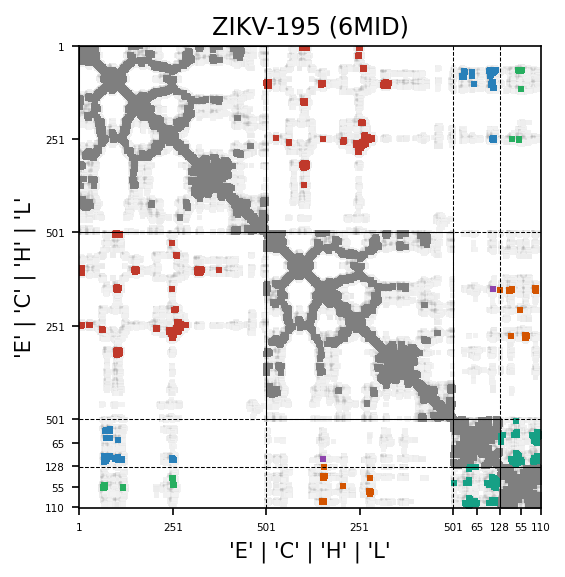

In [6]:
pdb_6mid.plot_contacts_four('E','C','H','L', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="ZIKV-195 (6MID)",
                            tick_size=5, font_size=10)

(<Figure size 450x450 with 1 Axes>,
 <Axes: title={'center': 'EDE2 A11 (5LCV)'}, xlabel="'A' | 'B' | 'H' | 'L'", ylabel="'A' | 'B' | 'H' | 'L'">)

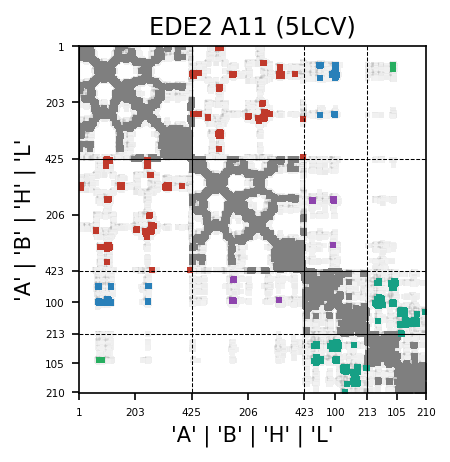

In [7]:
pdb_5lcv.plot_contacts_four('A','B','H','L', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="EDE2 A11 (5LCV)",
                            tick_size=5, font_size=10, size_in=3)

(<Figure size 450x450 with 1 Axes>,
 <Axes: title={'center': 'EDE1 C8 (5LBS)'}, xlabel="'A' | 'H' | 'L'", ylabel="'A' | 'H' | 'L'">)

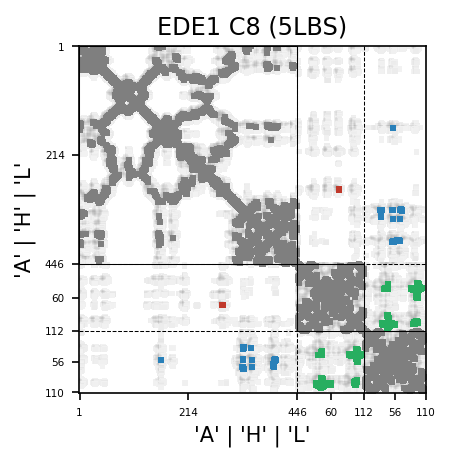

In [8]:
pdb_5lbs.plot_contacts_three('A','H','L', n_ticks=3, cutoff=1.1, gray_cutoff=3.0, title="EDE1 C8 (5LBS)",
                            tick_size=5, font_size=10, size_in=3)

(<Figure size 300x300 with 1 Axes>,
 <Axes: title={'center': 'ZKV-117 (5KVE)'}, xlabel="'E' | 'L'", ylabel="'E' | 'L'">)

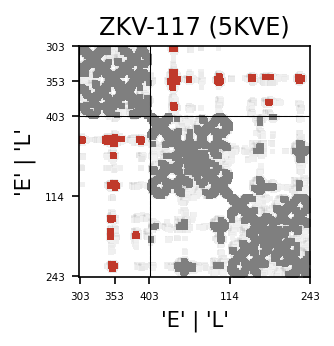

In [9]:
pdb_5kve.plot_contacts_two('E', 'L', n_ticks=3, cutoff=1.1, gray_cutoff=2.0, title="ZKV-117 (5KVE)",
                            tick_size=5, font_size=10, size_in=2)